# Redes neuronales

Las redes neuronales artificiales son modelos formados por unidades simples, las neuronas, organizadas en capas y conectadas entre sí. Su capacidad de aprender relaciones no lineales muy complejas, sumada a la disponibilidad de grandes volúmenes de datos y de procesadores gráficos, dio origen al aprendizaje profundo, que domina hoy el análisis de imágenes, señales y texto, y tiene un papel creciente en las geociencias {cite}`goodfellow2016,reichstein2019`.

## Del perceptrón a la red multicapa

El perceptrón, inspirado en la neurona biológica, calcula una suma ponderada de sus entradas más un sesgo, $z = w^T x + b$, y la pasa por una función de activación. Una sola neurona con activación sigmoide es exactamente una regresión logística. El perceptrón multicapa (MLP) organiza muchas neuronas en capas: una de entrada, una o más ocultas y una de salida, en la que cada neurona de una capa envía su salida a todas las de la siguiente. Las funciones de activación no lineales son las que dan potencia a la red: sin ellas, cualquier número de capas equivale a un modelo lineal. Las más comunes son la sigmoide y la tangente hiperbólica, que se saturan y pueden hacer que el gradiente se desvanezca, y la ReLU, $\max(0, z)$, la opción por defecto en las capas ocultas; en la salida se usa la sigmoide para clasificación binaria, la softmax para varias clases y la identidad para regresión.

El teorema de aproximación universal dice que una red con una sola capa oculta suficientemente grande puede aproximar cualquier función continua. En la práctica esa capa podría ser inviablemente grande y no aprender ni generalizar bien; las redes profundas, con varias capas, logran representaciones más eficientes.

## Entrenamiento: retropropagación

La red se entrena minimizando una función de pérdida con descenso por gradiente (capítulo {doc}`09_Optimizacion`). El gradiente respecto a todos los pesos se calcula con la retropropagación {cite}`rumelhart1986`, una aplicación ordenada de la regla de la cadena que propaga el error desde la salida hacia la entrada. La celda siguiente implementa desde cero, solo con `numpy`, una red con una capa oculta y la entrena para clasificar un problema no lineal, para que el mecanismo quede a la vista.

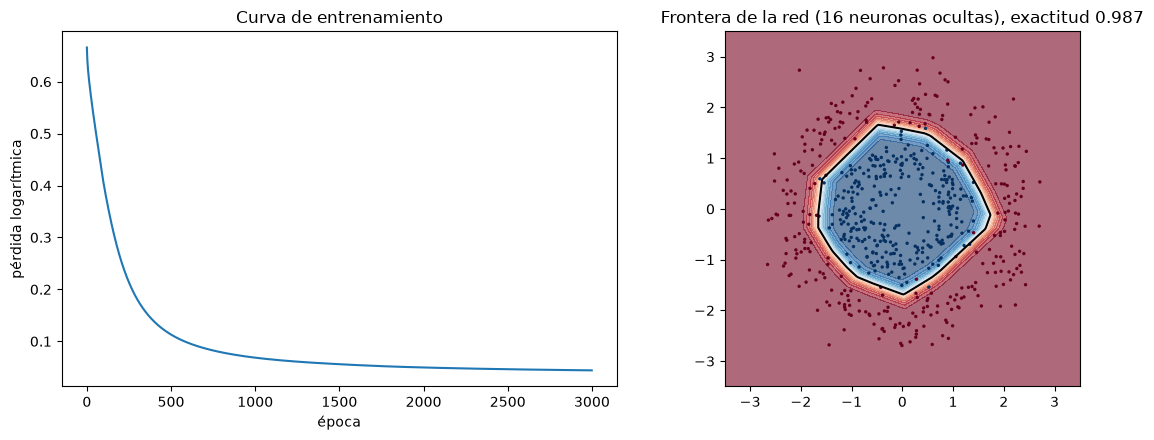

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(13)

# datos: dos clases en forma de anillos (no separables linealmente)
n = 600
r = np.concatenate([rng.normal(1, 0.25, n // 2), rng.normal(2.2, 0.3, n // 2)])
t = rng.uniform(0, 2 * np.pi, n)
X = np.column_stack([r * np.cos(t), r * np.sin(t)])
y = np.repeat([0, 1], n // 2).astype(float)[:, None]

def relu(z): return np.maximum(0, z)
def sigm(z): return 1 / (1 + np.exp(-z))

h = 16
W1 = rng.normal(0, np.sqrt(2 / 2), (2, h)); b1 = np.zeros(h)
W2 = rng.normal(0, np.sqrt(2 / h), (h, 1)); b2 = np.zeros(1)
alfa, hist = 0.1, []
for epoca in range(3000):
    # propagación hacia adelante
    Z1 = X @ W1 + b1; A1 = relu(Z1)
    p = sigm(A1 @ W2 + b2)
    hist.append(-np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)))
    # retropropagación (regla de la cadena)
    dZ2 = (p - y) / n
    dW2 = A1.T @ dZ2; db2 = dZ2.sum(0)
    dZ1 = (dZ2 @ W2.T) * (Z1 > 0)
    dW1 = X.T @ dZ1; db1 = dZ1.sum(0)
    # descenso por gradiente
    W1 -= alfa * dW1; b1 -= alfa * db1; W2 -= alfa * dW2; b2 -= alfa * db2

g1, g2 = np.meshgrid(np.linspace(-3.5, 3.5, 200), np.linspace(-3.5, 3.5, 200))
G = np.column_stack([g1.ravel(), g2.ravel()])
pg = sigm(relu(G @ W1 + b1) @ W2 + b2).reshape(g1.shape)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(hist); ax[0].set_xlabel('época'); ax[0].set_ylabel('pérdida logarítmica'); ax[0].set_title('Curva de entrenamiento')
ax[1].contourf(g1, g2, pg, 20, cmap='RdBu_r', alpha=0.6); ax[1].contour(g1, g2, pg, [0.5], colors='k')
ax[1].scatter(*X.T, c=y[:, 0], cmap='RdBu_r', s=6, edgecolor='none'); ax[1].set_aspect('equal')
ax[1].set_title(f'Frontera de la red (16 neuronas ocultas), exactitud {np.mean((p > 0.5) == y):.3f}')
plt.tight_layout(); plt.show()

## Redes en la práctica

Para problemas tabulares pequeños o medianos, `scikit-learn` ofrece `MLPClassifier` y `MLPRegressor`; para redes grandes se usan PyTorch, TensorFlow o JAX. Las decisiones principales son la arquitectura (número de capas y neuronas), la función de activación, el optimizador (Adam es la opción por defecto), la tasa de aprendizaje, el tamaño del minilote y la regularización: penalización L2 de los pesos, abandono (dropout), que apaga neuronas al azar durante el entrenamiento, y parada temprana, que detiene el entrenamiento cuando el error de validación deja de mejorar. Las entradas deben escalarse. Con datos tabulares, las redes no suelen superar a los ensambles de árboles bien ajustados, y son más difíciles de entrenar e interpretar; su ventaja aparece con datos de gran dimensión y estructura, como imágenes o series.

La celda siguiente entrena una red con `scikit-learn` para estimar la resistencia de una roca a partir de propiedades índice, con parada temprana, y la compara con una regresión lineal.

In [2]:
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

m = 800
por = rng.uniform(1, 30, m); vp = 6.3 - 0.11 * por + rng.normal(0, 0.3, m); sat = rng.uniform(0, 1, m)
ucs = 220 * np.exp(-0.08 * por) * (1 - 0.35 * sat) + 6 * vp + rng.normal(0, 6, m)    # relación no lineal con interacción
Xr = np.column_stack([por, vp, sat])
for nom, mod in [('regresión lineal', LinearRegression()),
                 ('red neuronal (32-16)', MLPRegressor(hidden_layer_sizes=(32, 16), early_stopping=True, max_iter=3000, random_state=0))]:
    print(f'{nom:22s} R² en validación cruzada {cross_val_score(make_pipeline(StandardScaler(), mod), Xr, ucs, cv=5, scoring="r2").mean():.3f}')

regresión lineal       R² en validación cruzada 0.907


red neuronal (32-16)   R² en validación cruzada 0.965


## Arquitecturas especializadas

Las redes convolucionales (CNN) están diseñadas para datos con estructura espacial, como imágenes o modelos de elevación. En lugar de conectar todas las entradas con todas las neuronas, aplican filtros pequeños (núcleos) que se deslizan sobre la imagen y detectan rasgos locales, como bordes o texturas, compartiendo los pesos en toda la imagen. El paso (stride) y el relleno (padding) controlan el tamaño de la salida; las capas de agrupamiento (pooling máximo o promedio) reducen la resolución y dan invariancia a pequeños desplazamientos. Al apilar capas, la red aprende rasgos cada vez más abstractos; al final, la salida se aplana y pasa por capas totalmente conectadas que clasifican. Las arquitecturas de segmentación, como la U-Net, producen un mapa de clases píxel a píxel y se usan para cartografiar deslizamientos en imágenes de satélite. La celda siguiente aplica a mano una convolución y un agrupamiento máximo para mostrar la operación básica.

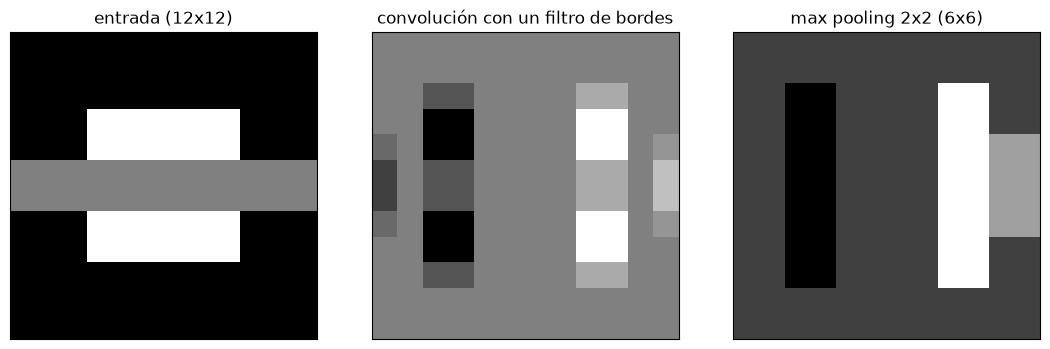

In [3]:
from scipy.signal import convolve2d
img = np.zeros((12, 12)); img[3:9, 3:9] = 1; img[5:7, :] = 0.5
nucleo = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])         # detector de bordes verticales
conv = convolve2d(img, nucleo, mode='same')
pool = conv.reshape(6, 2, 6, 2).max(axis=(1, 3))
fig, axs = plt.subplots(1, 3, figsize=(11, 3.5))
for a, im, t_ in zip(axs, [img, conv, pool], ['entrada (12x12)', 'convolución con un filtro de bordes', 'max pooling 2x2 (6x6)']):
    a.imshow(im, cmap='gray'); a.set_title(t_); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

Las redes recurrentes (RNN), y en particular las LSTM, procesan secuencias manteniendo una memoria del pasado y se usan en series de tiempo, como la predicción de caudales o de desplazamientos de laderas a partir de la lluvia. Los transformadores, basados en mecanismos de atención, las están reemplazando en muchas tareas.

Las redes neuronales informadas por la física (PINN) {cite}`raissi2019` incorporan las leyes físicas en el entrenamiento: la función de pérdida incluye, además del error frente a los datos, el residuo de la ecuación diferencial que gobierna el sistema (por ejemplo, la ecuación de difusión de la presión de poros en una ladera). Así las predicciones son coherentes con la física aun con pocos datos, en la línea de la ciencia de datos guiada por la teoría {cite}`karpatne2017`. El notebook 19 del curso desarrolla un ejemplo.

## Para profundizar

Los capítulos 6 a 9 de {cite}`goodfellow2016` cubren las redes prealimentadas, la regularización, la optimización y las redes convolucionales; el capítulo 10 de {cite}`james2021` es una introducción más accesible. {cite:t}`reichstein2019` discuten el aprendizaje profundo en las ciencias de la Tierra. Los notebooks 19 del curso implementan redes con `scikit-learn` y PINN.